# PART II

In [1]:
import time, numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,confusion_matrix, roc_curve, auc)
import matplotlib.pyplot as plt
import seaborn as sns
import random

In [2]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

In [3]:
df = pd.read_csv("dataset_cleaned.csv").replace("?", np.nan)
df = df.dropna(subset=[df.columns[-1]])
X_df = pd.get_dummies(df.iloc[:, :-1], drop_first=True)
y_sr = df.iloc[:, -1]
scaler = StandardScaler()
X_np = scaler.fit_transform(X_df).astype("float32")
y_np = y_sr.values.astype("float32").reshape(-1, 1)
X_train, X_tmp, y_train, y_tmp = train_test_split(X_np, y_np, test_size=0.30, random_state=42, stratify=y_np)
X_val,   X_test, y_val,   y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=42, stratify=y_tmp)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def to_t(a): return torch.tensor(a, dtype=torch.float32, device=device)
X_train_t, y_train_t = to_t(X_train), to_t(y_train)
X_val_t,   y_val_t   = to_t(X_val),   to_t(y_val)
X_test_t,  y_test_t  = to_t(X_test),  to_t(y_test)

In [4]:
class NNet(nn.Module):
    def __init__(self, input_size, hidden=(64, 32), dropout=0.3, batchnorm=False, logits=False):
        super().__init__()
        layers = []
        in_f = input_size
        for h in hidden:
            layers += [nn.Linear(in_f, h)]
            if batchnorm: layers += [nn.BatchNorm1d(h)]
            layers += [nn.ReLU()]
            if dropout and dropout > 0: layers += [nn.Dropout(dropout)]
            in_f = h
        layers += [nn.Linear(in_f, 1)]
        if not logits:
            layers += [nn.Sigmoid()]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def init_xavier(m):
    if isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)

In [5]:
def make_loaders(batch_size=32):
    train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(TensorDataset(X_val_t,   y_val_t),   batch_size=batch_size)
    test_loader  = DataLoader(TensorDataset(X_test_t,  y_test_t),  batch_size=batch_size)
    return train_loader, val_loader, test_loader

def train_one(model, train_loader, val_loader, epochs=100, lr=1e-3, use_scheduler=False, early_stop_patience=None, criterion="bce"):
    if criterion == "bce_logits":
        y_flat = y_train_t.view(-1)
        pos = (y_flat == 1).sum().item(); neg = (y_flat == 0).sum().item()
        pos_weight = torch.tensor([neg / max(1, pos)], dtype=torch.float32, device=device)
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    else:
        loss_fn = nn.BCELoss()

    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', patience=6, factor=0.5) if use_scheduler else None

    best_val = float('inf'); best_state = None
    wait = 0
    tr_losses, va_losses = [], []
    t0 = time.time()

    for ep in range(epochs):
        model.train()
        run = 0.0
        for xb, yb in train_loader:
            opt.zero_grad()
            out = model(xb)
            loss = loss_fn(out, yb)
            loss.backward()
            opt.step()
            run += loss.item()
        tr_losses.append(run / max(1, len(train_loader)))

        model.eval()
        with torch.no_grad():
            vloss = 0.0
            for xv, yv in val_loader:
                vout = model(xv)
                vloss += loss_fn(vout, yv).item()
        vloss /= max(1, len(val_loader))
        va_losses.append(vloss)

        if sch: sch.step(vloss)

        if early_stop_patience is not None:
            if vloss < best_val - 1e-6:
                best_val = vloss
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
                wait = 0
            else:
                wait += 1
                if wait >= early_stop_patience:
                    break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, tr_losses, va_losses, time.time() - t0

def test_metrics(model):
    model.eval()
    with torch.no_grad():
        probs = model(X_test_t)
    preds = torch.round(probs)
    acc = accuracy_score(y_test_t.cpu(), preds.cpu())
    prec, rec, f1, _ = precision_recall_fscore_support(y_test_t.cpu(), preds.cpu(), average='binary', zero_division=0)
    return float(acc), float(prec), float(rec), float(f1), probs.detach().cpu().numpy(), preds.cpu().numpy()

In [6]:
input_size = X_train_t.shape[1]
results = []

## Dropout Rate, Batch Size, Learning Rate

In [7]:
for dr in [0.1, 0.3, 0.5]:
    train_loader, val_loader, test_loader = make_loaders(batch_size=32)
    m = NNet(input_size, hidden=(64,32), dropout=dr, batchnorm=False, logits=False).to(device)
    m.apply(init_xavier)
    m, tl, vl, tsec = train_one(m, train_loader, val_loader, epochs=80, lr=1e-3, use_scheduler=False, early_stop_patience=10, criterion="bce")
    acc, pr, rc, f1, _, _ = test_metrics(m)
    results.append(("Dropout", dr, 32, 1e-3, acc, f1, tsec))

for bs in [16, 32, 64]:
    train_loader, val_loader, test_loader = make_loaders(batch_size=bs)
    m = NNet(input_size, hidden=(64,32), dropout=0.3, batchnorm=False, logits=False).to(device)
    m.apply(init_xavier)
    m, tl, vl, tsec = train_one(m, train_loader, val_loader, epochs=80, lr=1e-3, use_scheduler=False, early_stop_patience=10, criterion="bce")
    acc, pr, rc, f1, _, _ = test_metrics(m)
    results.append(("BatchSize", 0.3, bs, 1e-3, acc, f1, tsec))

for lr in [1e-3, 5e-4, 1e-4]:
    train_loader, val_loader, test_loader = make_loaders(batch_size=32)
    m = NNet(input_size, hidden=(64,32), dropout=0.3, batchnorm=False, logits=False).to(device)
    m.apply(init_xavier)
    m, tl, vl, tsec = train_one(m, train_loader, val_loader, epochs=80, lr=lr, use_scheduler=False, early_stop_patience=10, criterion="bce")
    acc, pr, rc, f1, _, _ = test_metrics(m)
    results.append(("LearningRate", 0.3, 32, lr, acc, f1, tsec))

## HYPERPARAMETER TUNING

In [8]:
class BasicNN(nn.Module):
    def __init__(self, input_size, dropout_rate=0.2):
        super(BasicNN, self).__init__()
        self.network = nn.Sequential(nn.Linear(input_size, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(dropout_rate),nn.Linear(64, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(dropout_rate),nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(dropout_rate),nn.Linear(64, 1), nn.Sigmoid())
    def forward(self, x):
        return self.network(x)
dropout_values = [0.1, 0.2, 0.3, 0.4, 0.5]
results = []
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
for dropout in dropout_values:
    print(f"\nTraining with Dropout = {dropout}")

    model = BasicNN(input_size, dropout_rate=dropout).to(device)
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200, eta_min=1e-6)

    best_val_accuracy = 0.0
    best_model_state = None

    for epoch in range(200):
        model.train()
        total_loss, correct, total = 0, 0, 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            preds = model(xb)
            loss = criterion(preds, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()
            predicted = (preds >= 0.5).float()
            correct += (predicted == yb).sum().item()
            total += yb.size(0)

        model.eval()
        val_loss, correct, total = 0, 0, 0

        with torch.no_grad():
            for xv, yv in val_loader:
                xv, yv = xv.to(device), yv.to(device)
                val_preds = model(xv)
                val_loss += criterion(val_preds, yv).item()
                predicted = (val_preds >= 0.5).float()
                correct += (predicted == yv).sum().item()
                total += yv.size(0)

        val_accuracy = 100 * correct / total
        scheduler.step()

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_model_state = model.state_dict().copy()
    model.load_state_dict(best_model_state)
    model.eval()
    X_test_tensor = torch.FloatTensor(X_test).to(device)
    y_test_tensor = torch.FloatTensor(y_test).reshape(-1, 1).to(device)

    with torch.no_grad():
        test_preds = model(X_test_tensor)
        test_preds_binary = (test_preds >= 0.5).float()
    y_test_np = y_test_tensor.cpu().numpy().flatten()
    preds_np = test_preds_binary.cpu().numpy().flatten()
    test_accuracy = accuracy_score(y_test_np, preds_np)
    print(f"Test Accuracy: {test_accuracy*100:.2f}%")

    results.append({'Dropout': dropout,'Test Accuracy': f"{test_accuracy*100:.2f}%"})

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

results_df.to_csv('dropout_tuning_results.csv', index=False)



Training with Dropout = 0.1
Test Accuracy: 80.87%

Training with Dropout = 0.2
Test Accuracy: 75.65%

Training with Dropout = 0.3
Test Accuracy: 73.04%

Training with Dropout = 0.4
Test Accuracy: 75.65%

Training with Dropout = 0.5
Test Accuracy: 75.65%
DROPOUT HYPERPARAMETER TUNING
 Dropout Test Accuracy
     0.1        80.87%
     0.2        75.65%
     0.3        73.04%
     0.4        75.65%
     0.5        75.65%


In [9]:
tuning_df = pd.DataFrame(results, columns=["Hyperparam", "Dropout", "BatchSize", "LR", "TestAcc", "TestF1", "TrainSec"])
print("\nTuning Results")
display(tuning_df.sort_values("TestAcc", ascending=False))


Tuning Results


,Hyperparam,Dropout,BatchSize,LR,TestAcc,TestF1,TrainSec
0,NaN,0.1,NaN,NaN,NaN,NaN,NaN
1,NaN,0.2,NaN,NaN,NaN,NaN,NaN
2,NaN,0.3,NaN,NaN,NaN,NaN,NaN
3,NaN,0.4,NaN,NaN,NaN,NaN,NaN
4,NaN,0.5,NaN,NaN,NaN,NaN,NaN


In [10]:
best_dropout = float(tuning_df.loc[tuning_df["Hyperparam"]=="Dropout"].sort_values("TestAcc", ascending=False).iloc[0]["Dropout"]) if (tuning_df["Hyperparam"]=="Dropout").any() else 0.3
best_bs      = int(tuning_df.loc[tuning_df["Hyperparam"]=="BatchSize"].sort_values("TestAcc", ascending=False).iloc[0]["BatchSize"]) if (tuning_df["Hyperparam"]=="BatchSize").any() else 32
best_lr      = float(tuning_df.loc[tuning_df["Hyperparam"]=="LearningRate"].sort_values("TestAcc", ascending=False).iloc[0]["LR"]) if (tuning_df["Hyperparam"]=="LearningRate").any() else 5e-4

train_loader, val_loader, test_loader = make_loaders(batch_size=best_bs)

opt_model = NNet(input_size, hidden=(128,64,32), dropout=best_dropout, batchnorm=True, logits=False).to(device)
opt_model.apply(init_xavier)

opt_model, train_losses, val_losses, train_time = train_one(opt_model, train_loader, val_loader,epochs=120, lr=best_lr, use_scheduler=True, early_stop_patience=15, criterion="bce")

acc, prec, rec, f1, y_prob, y_pred = test_metrics(opt_model)
print(f"\n Optimized Model Performance \nAccuracy={acc:.4f}  Precision={prec:.4f}  Recall={rec:.4f}  F1={f1:.4f}  TrainTime={train_time:.2f}s")


 Optimized Model Performance 
Accuracy=0.7652  Precision=0.6970  Recall=0.5750  F1=0.6301  TrainTime=0.46s


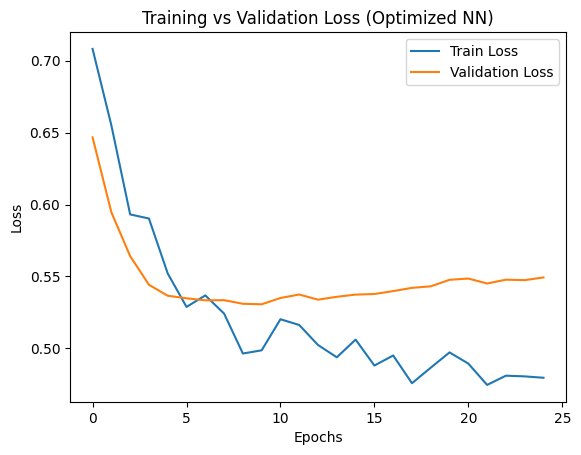

In [11]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.title("Training vs Validation Loss (Optimized NN)")
plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.legend(); plt.show()

**Descryption:-**
For an optimised neural network, the graph shows two lines that compare training loss and validation loss over training epochs.  Training loss, which illustrates how well the model learns from training data, is represented by the blue line.  Validation loss, which gauges performance on unobserved data, is represented by the orange line.  In order to show that the model is learning, both lines should drop across epochs.  Overfitting is indicated if the validation loss rises while the training loss falls.  Both lines in a well-optimized model decrease together and converge to low values, indicating strong generalisation.

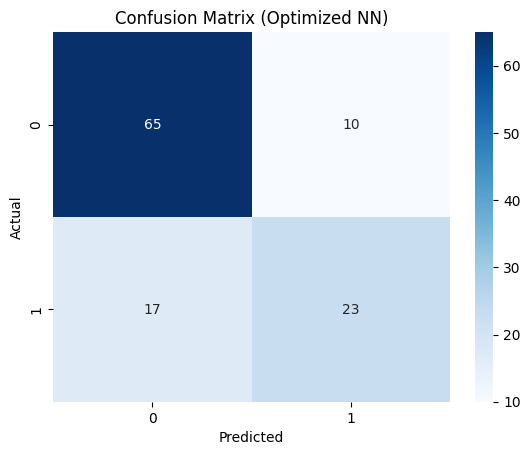

In [12]:
cm = confusion_matrix(y_test_t.cpu().numpy(), y_pred)
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d")
plt.title("Confusion Matrix (Optimized NN)"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

**Decryption:-**
The model prediction accuracy is displayed as a coloured heatmap created by the code.  By comparing the actual test labels with the model predictions, Line 1 computes the confusion matrix.  It appears as a blue grid with numbers in each cell on line 2.  The axis labels and title are added in lines 3-5.  The final visualisation is displayed in line 6.

 Four cells are visible in the 2x2 grid:


 Top-left (True Negatives): Accurately anticipated zero

 Top-right (False Positives): 0 instead of 1 as predicted

 False Negatives, bottom-left:  0 was predicted, but it was 1.

 True Positives, bottom-right:  Predicted correctly: 1

 Higher numbers are indicated by darker blue.  The optimised model delivers accurate predictions when there is a strong diagonal (high top-left and bottom-right).  Prediction mistakes are indicated by high off-diagonal readings.**bold text**

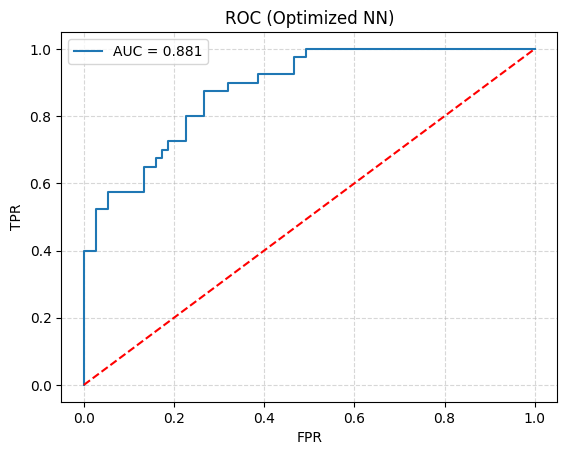

In [13]:
fpr, tpr, _ = roc_curve(y_test_t.cpu().numpy(), y_prob)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1],[0,1],'r--'); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC (Optimized NN)")
plt.legend(); plt.grid(True, linestyle="--", alpha=0.5); plt.show()

**Decryption**
Description of the ROC Curve Graph  Just
 The graph displays a curving line that moves from the bottom-left corner (0,0) to the top-left corner (0,1).  The model's capacity to differentiate between positive and negative classes at various decision thresholds is represented by the curve.  A random classifier (worthless model) is represented by a red diagonal dashed line.  The model outperforms random guessing, as shown by the curved blue line above the diagonal.  The AUC value (shown in the legend) has a range of 0 to 1, where values near 0.5 indicate poor model performance and values closer to 1 indicate great model performance.  The better the optimised neural network classifies the data, the more the curve bends towards the top-left.

In [14]:
torch.save(opt_model.state_dict(), "a2_part_2_weights_pranayla_vpamulap.pkl")

## References:
1. https://pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html
2. https://pytorch.org/docs/stable/generated/torch.nn.BCELoss.html
3. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
4. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
5. https://seaborn.pydata.org/generated/seaborn.heatmap.html
6. https://arxiv.org/pdf/1702.05373.pdf
7. https://pytorch.org/vision/main/generated/torchvision.datasets.ImageFolder.html
8. https://pytorch.org/tutorials/beginner/basics/data_tutorial.html
9. https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html
10. https://pytorch.org/docs/stable/nn.html
11. https://github.com/TylerYep/torchinfo
12. https://pytorch.org/tutorials/beginner/saving_loading_models.html
13. https://torchmetrics.readthedocs.io/en/stable/classification/accuracy.html
14. https://en.wikipedia.org/wiki/F-score
15. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html
16. https://seaborn.pydata.org/generated/seaborn.heatmap.html
17. https://torchmetrics.readthedocs.io/en/stable/classification/confusion_matrix.html
18. https://developers.google.com/machine-learning/crash-course/classification/roc-and-auc
19. https://torchmetrics.readthedocs.io/en/stable/classification/roc.html
20. https://docs.python.org/3/library/time.html

## Contribution Table :

### Team Contribution Summary

| Step | Teammate | Contribution % |
|------|----------|----------------|
| 1 | pranayla & vpampulap | each 50% |
| 2 | pranayla & vpampulap | each 50% |
| 3 | pranayla & vpampulap | each 50% |
| 4 | pranayla & vpampulap | each 50% |
| 5 | pranayla & vpampulap | each 50% |
| 6 | pranayla & vpampulap | each 50% |
| 7 | pranayla & vpampulap | each 50% |

